In [25]:
import torch
import torch.nn as nn
import torch.nn.init as init
import numpy as np
import matplotlib.pyplot as plt
from torch.autograd import grad
import time
import random
import math
import pandas as pd

def set_random_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True  # 关闭确定性，换速度
    torch.backends.cudnn.benchmark = True       # 开启CUDA算法自动调优（float64下收益显著）
    torch.backends.cudnn.enabled = True         # 强制开启cudnn
    if torch.cuda.is_available():
        torch.cuda.empty_cache()  # 初始化清空GPU缓存
    print(f"随机种子设置为: {seed}")
set_random_seed(42)
torch.set_default_dtype(torch.float32)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

随机种子设置为: 42
Using device: cuda


In [26]:
class TrunkBranchNet(nn.Module):
    """TB-net PINN框架：一个trunk，对应多个branch分别预测(u~, v~, p~)"""

    def __init__(self, trunk_layers, branch_layers, output_dim=3):
        super(TrunkBranchNet, self).__init__()

        trunk = []
        for i in range(len(trunk_layers) - 1):
            trunk.append(nn.Linear(trunk_layers[i], trunk_layers[i + 1]))
            trunk.append(nn.Tanh())
        self.trunk_net = nn.Sequential(*trunk)

        # 分支网络：每个输出物理量一个分支
        self.branch_nets = nn.ModuleList()
        for _ in range(output_dim):
            branch = []
            for i in range(len(branch_layers) - 1):
                branch.append(nn.Linear(branch_layers[i], branch_layers[i + 1]))
                if i < len(branch_layers) - 2:
                    branch.append(nn.Tanh())
            self.branch_nets.append(nn.Sequential(*branch))

        self.output_layers = nn.ModuleList(
            [nn.Linear(branch_layers[-1], 1) for _ in range(output_dim)]
        )
    def forward(self, x):
        # x[:, :2] = [x*, y*]
        trunk_out = self.trunk_net(x[:, :2])
        outs = []
        for i, branch in enumerate(self.branch_nets):
            b = branch(trunk_out)
            o = self.output_layers[i](b)
            outs.append(o)
        # 输出无量纲: [u~, v~, p~]
        return torch.cat(outs, dim=1)

trunk_layers = [2, 50,50,50, 50]
branch_layers = [50, 50, 50, 50]
output_dim = 3
net = TrunkBranchNet(trunk_layers, branch_layers, output_dim).to(device)

In [27]:
def get_physical_parameters():
    params = {
        'rho': 960.0,        # kg/m^3（和论文一致）
        'mu': 8.526e-4,      # kg/(m·s)（和论文一致）          
        'dp': 1e-4,          # m（论文原值：0.1mm）
        'L': 0.02,           # m, 方形板水平边长
    
        # 'x_center': 0.01,    # 双域界面位置（方形板中点）
        'p_outlet': 1e5,     # Pa（和论文一致）
        'v_inlet': 1.0 / 960.0,  # m/s（和论文一致）
        # 双域孔隙率（论文值）
        'eps1': 0.2,         # 区域 1 （方形板背景）
        'eps2': 0.5,         # 区域 2 （圆形区域）

        # 圆形几何尺寸（适配0.02m方形板）
        'xc': 0.01,          # 圆心x坐标（方形板中心）
        'yc': 0.01,          # 圆心y坐标（方形板中心）
        'R': 0.003,          # 圆半径（避免超出方形板）
        
        # 特征尺度（适配0.02m方形板）
        'mu_0':8.526e-4,   
        'k_0':1e-12,         # 
        'V_0':1e-3,         #定
        'L_0':0.02,         # 
    }
    # 特征压力自动计算（适配新的L_0=0.02）
    params['P_0'] = (params['L_0'] * params['mu_0'] * params['V_0']) / params['k_0']
    return params

def permeability(eps, dp):
    """Ergun 关系 (式6): K = dp^2 * eps^3 / [150 (1-eps)^2]"""
    return (dp ** 2) * (eps ** 3) / (150.0 * (1.0 - eps) ** 2)
params = get_physical_parameters()

In [28]:
def latin_hypercube_sampling(n_samples, n_dim): ##依据点的数量划分段，比如3个点，那么x被划分为3个等宽的小区间，perm说明了先采哪个小区间而已
    """超拉丁立方采样"""
    samples = np.zeros((n_samples, n_dim)) ##行，列（dim）
    for i in range(n_dim):  
        perm = np.random.permutation(n_samples) #随机分配每层的采样顺序
        samples[:, i] = (perm + np.random.rand(n_samples)) / n_samples  ##如n_samples=3、i=0（处理 x 轴）、perm=[1,0,2]
        #假设生成[0.4, 0.7, 0.2] ； 1+0.4=1.4、0+0.7=0.7、2+0.2=2.2 1.4/3≈0.4667、0.7/3≈0.2333、2.2/3≈0.7333归一化的
    return samples
##指定使用超拉丁采样的区域
def sample_region_lhs(n_samples, region_id, params):

    L  = params['L']
    xc = params['xc']
    yc = params['yc']
    R  = params['R']

    xs_list = []
    ys_list = []

    while True:
        need = n_samples - sum(len(a) for a in xs_list) #计算还需要多少个符合条件的点
        if need <= 0: #如果够了就直接退出
            break

        n_batch = max(1000, int(1.5 * need) + 1)
        unit = latin_hypercube_sampling(n_batch, 2)  # numpy, in [0,1]
        x_b = unit[:, 0:1] * L
        y_b = unit[:, 1:2] * L
        r_sq = (x_b - xc) ** 2 + (y_b - yc) ** 2
    
        if region_id == 1: #孔外
            mask = (r_sq > R ** 2 )
        else:  ##孔内
            mask = (r_sq < R ** 2 )

        x_sel = x_b[mask].reshape(-1, 1)
        y_sel = y_b[mask].reshape(-1, 1)

        if x_sel.shape[0] > 0: 
            xs_list.append(x_sel)
            ys_list.append(y_sel)

    x_all = np.vstack(xs_list)[:n_samples]
    y_all = np.vstack(ys_list)[:n_samples]

    x_phys = torch.tensor(x_all,dtype=torch.get_default_dtype(),device=device)
    y_phys = torch.tensor(y_all,dtype=torch.get_default_dtype(),device=device)
    return x_phys, y_phys

In [29]:
##采点函数，包含圆内，圆形，边界
def generate_training_data_two_region(
        params,
        n_dom_out=6000,   # ★ 孔外 PDE 采样点数
        n_dom_in=3000,     # ★ 孔内 PDE 采样点数
):

    L  = params['L']
    xc = params['xc']
    yc = params['yc']
    R  = params['R']

    # ===== 1. 孔外 / 孔内 区域采样（PDE 内点） =====
    # 孔外：region 1
    x_dom_out_phys, y_dom_out_phys = sample_region_lhs( n_dom_out, region_id=1, params=params )
    x_dom_in_phys, y_dom_in_phys = sample_region_lhs( n_dom_in, region_id=2, params=params )
    x_dom_phys = torch.cat([x_dom_out_phys, x_dom_in_phys], dim=0)
    y_dom_phys = torch.cat([y_dom_out_phys, y_dom_in_phys], dim=0)
    # 无量纲化 + 要求梯度
    x_dom_out = (x_dom_out_phys / L* 2 - 1).clone().detach().requires_grad_(True)
    y_dom_out = (y_dom_out_phys / L* 2 - 1).clone().detach().requires_grad_(True)

    x_dom_in  = (x_dom_in_phys  / L* 2 - 1).clone().detach().requires_grad_(True)
    y_dom_in  = (y_dom_in_phys  / L* 2 - 1).clone().detach().requires_grad_(True)
    
    x_dom_nd = torch.cat([x_dom_out, x_dom_in], dim=0)
    y_dom_nd = torch.cat([y_dom_out, y_dom_in], dim=0)
    data_dict = {
        # --- PDE 域内点 ---
        'dom_out': (x_dom_out, y_dom_out),            # 
        'dom_in':  (x_dom_in,  y_dom_in),             # 
        'dom_nd': (x_dom_nd, y_dom_nd),               #无量纲数据点
        
        'dom_out_phys': (x_dom_out_phys, y_dom_out_phys),
        'dom_in_phys':  (x_dom_in_phys,  y_dom_in_phys),
        'dom_phys':  (x_dom_phys, y_dom_phys)        #有量纲数据点
    }
    return data_dict
data_dict = generate_training_data_two_region( params,n_dom_out=6000,n_dom_in=3000) ##点

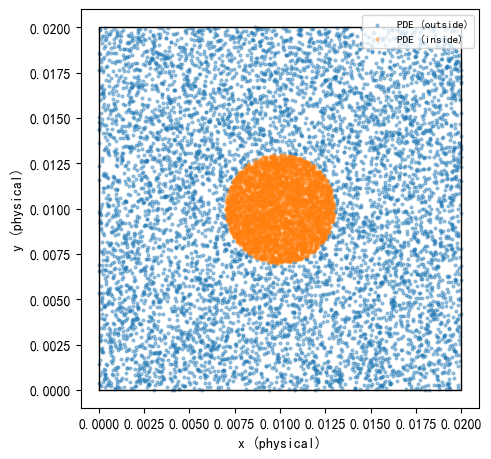

In [30]:
##绘制采样图
def plot_sampling_two_region(data_dict, params):
    
    L = params['L']
    # 从 data_dict 里拿物理坐标（都是 torch.Tensor）
    x_out_phys, y_out_phys = data_dict['dom_out_phys']
    x_in_phys,  y_in_phys  = data_dict['dom_in_phys']

    # 转成 numpy
    def to_np(t):
        if t is None:
            return None
        else:
            return t.detach().cpu().numpy() ##cpu()把坐标放到cpu上，才能转numpy

    x_out_np,  y_out_np  = to_np(x_out_phys),  to_np(y_out_phys)
    x_in_np,   y_in_np   = to_np(x_in_phys),   to_np(y_in_phys)

    plt.figure(figsize=(5, 5))  #

    plt.scatter(x_out_np, y_out_np, s=4, alpha=0.4, label="PDE (outside)")
    plt.scatter(x_in_np, y_in_np, s=4, alpha=0.4, label="PDE (inside)")
    # 5) 画出矩形边界轮廓
    rect_x = [0, L, L, 0, 0]
    rect_y = [0, 0, L, L, 0]
    plt.plot(rect_x, rect_y, 'k-', linewidth=1.0)

    plt.xlabel("x (physical)")
    plt.ylabel("y (physical)")
    plt.axis("scaled")
    plt.xlim(-0.001, L+0.001)
    plt.ylim(-0.001, L+0.001)
    plt.legend(loc="upper right", fontsize=8)
    plt.tight_layout()
    plt.show()
    
    
data = generate_training_data_two_region(
    params,
    n_dom_out=7000,  
    n_dom_in=4000)
plot_sampling_two_region(data, params)

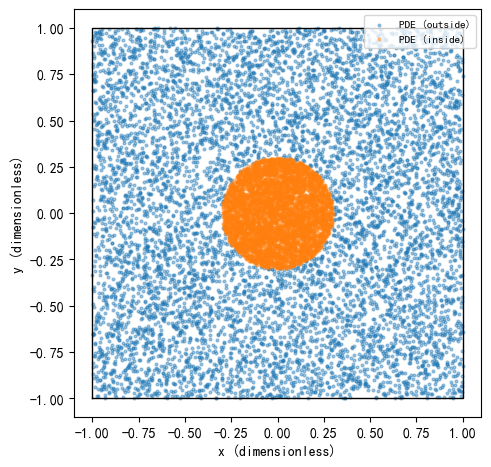

In [31]:
##绘制采样图
def plot_sampling_two_region(data_dict, params):
    
    # 从 data_dict 里拿物理坐标（都是 torch.Tensor）
    x_out_phys, y_out_phys = data_dict['dom_out']
    x_in_phys,  y_in_phys  = data_dict['dom_in']
    # 转成 numpy
    def to_np(t):
        if t is None:
            return None
        else:
            return t.detach().cpu().numpy() ##cpu()把坐标放到cpu上，才能转numpy

    x_out_np,  y_out_np  = to_np(x_out_phys),  to_np(y_out_phys)
    x_in_np,   y_in_np   = to_np(x_in_phys),   to_np(y_in_phys)
    plt.figure(figsize=(5, 5))  # 横向窄一点，接近你几何比例

    # 1) 孔外 PDE 点
    plt.scatter(x_out_np, y_out_np, s=4, alpha=0.4, label="PDE (outside)")
    plt.scatter(x_in_np, y_in_np, s=4, alpha=0.4, label="PDE (inside)")
    # 5) 画出矩形边界轮廓
    rect_x = [-1, 1, 1, -1, -1]
    rect_y = [-1, -1, 1, 1, -1]
    plt.plot(rect_x, rect_y, 'k-', linewidth=1.0)
    plt.xlabel("x (dimensionless)")
    plt.ylabel("y (dimensionless)")
    plt.axis("scaled")
    # plt.xlim(-0.05, 1+0.05)
    # plt.ylim(-0.05, 1+0.05)
    plt.legend(loc="upper right", fontsize=8)
    plt.tight_layout()
    plt.show()
    
    
data = generate_training_data_two_region(
    params,
    n_dom_out=8000,  
    n_dom_in=5000,  )
plot_sampling_two_region(data, params)

In [32]:
def gradients(y, x):
    return grad(y, x,grad_outputs=torch.ones_like(y),create_graph=True,retain_graph=True)[0]

In [33]:
##out_net
def forward_with_hard_bc(net, coords, params):

    raw = net(coords)            # (N, 3) = [u~, v~, p~]
    u_tilde = raw[:, 0:1]
    v_tilde = raw[:, 1:2]
    p_tilde = raw[:, 2:3]

    x = coords[:, 0:1]           # x* ∈ [0,1]
    y = coords[:, 1:2]           # y* ∈ [0,1]
    # 无量纲的入口速度 / 出口压力
    v_in_star  = params['v_inlet']  / params['V_0']
    p_out_star = params['p_outlet'] / params['P_0']
    # --- 硬约束边界条件 ---
    # 1) 左右壁 & 底部：u = 0，在 x=-1, x=1, y=-1 处因子为0
    wall_mask = (1.0 - x**2 ) * (1 + y)  # 壁面掩码（壁面处=0，内部≈1）
    u_star = wall_mask * u_tilde  # 加小偏置避免梯度消失
    # 2) 入口：v = v_in_star + y * v~ ⇒ y=-1 时 v = v_in_star
    v_star = v_in_star + (1 + y) * v_tilde
    # 3) 出口：y=1 处 p = p_out_star
    p_star = p_out_star + (1.0 - y) * p_tilde
    return u_star, v_star, p_star

In [34]:
def governing_equations(net, x_star, y_star, params):
    
    coords = torch.cat([x_star, y_star], dim=1).requires_grad_(True)
    u, v, p = forward_with_hard_bc(net, coords, params)
    
    # 计算一阶导数
    gu = gradients(u, coords)
    gv = gradients(v, coords)
    gp = gradients(p, coords)
    u_x, u_y = gu[:, 0:1], gu[:, 1:2]
    v_x, v_y = gv[:, 0:1], gv[:, 1:2]
    p_x, p_y = gp[:, 0:1], gp[:, 1:2]

    # 计算二阶导数
    u_xx = gradients(u_x, coords)[:, 0:1]
    u_yy = gradients(u_y, coords)[:, 1:2]
    v_xx = gradients(v_x, coords)[:, 0:1]
    v_yy = gradients(v_y, coords)[:, 1:2]

    # 提取物理参数
    L = params['L']           # 物理长度（m），方形板边长
    eps1, eps2 = params['eps1'], params['eps2']
    mu, dp = params['mu'], params['dp']
    V_0, P_0 = params['V_0'], params['P_0']
    mu_0, k_0 = params['mu_0'], params['k_0']
    
    # 物理坐标下的圆心和半径
    xc_phys = params['xc']    # 物理圆心x (m)
    yc_phys = params['yc']    # 物理圆心y (m)
    R_phys = params['R']      # 物理半径 (m)

    # ========== 正确的无量纲化（关键修复） ==========
    # 无量纲化公式：x* = (x_phys / L)*2 - 1 → 反推：x_phys = (x* + 1) * L/2
    # 因此，圆心的无量纲坐标计算：
    xc_star = (xc_phys / L) * 2 - 1  # 无量纲圆心x，范围[-1,1]
    yc_star = (yc_phys / L) * 2 - 1  # 无量纲圆心y，范围[-1,1]
    R_star = (R_phys / L) * 2        # 无量纲半径（长度缩放因子是2/L）

    # 无量纲坐标下的距离平方（现在所有变量都在[-1,1]尺度下）
    r_sq_star = (x_star - xc_star)**2 + (y_star - yc_star)**2
    # 圆孔区域判断（无量纲）
    mask_hole = (r_sq_star <= R_star**2).float()  # 圆孔内=1，外=0
    mask_bg = 1.0 - mask_hole                     # 背景区域=1，圆孔内=0

    # 计算渗透率和无量纲参数（这部分你的代码是对的）
    K1 = permeability(eps1, dp)
    mu_nd = mu / mu_0  # 无量纲粘度
    mu_e1_nd = mu_nd / eps1
    K1_nd = K1 / k_0
    beta1 = mu_nd / K1_nd
    alpha1 = (k_0 / L**2) * mu_e1_nd

    K2 = permeability(eps2, dp)
    mu_e2_nd = mu_nd / eps2
    K2_nd = K2 / k_0
    beta2 = mu_nd / K2_nd
    alpha2 = (k_0 / L**2) * mu_e2_nd

    # 区域加权参数（背景+圆孔）
    alpha = mask_bg * alpha1 + mask_hole * alpha2
    beta = mask_bg * beta1 + mask_hole * beta2

    # 控制方程残差（无量纲形式）
    r_c = u_x + v_y  # 连续性方程残差
    r_mx = 2.0 * p_x + beta * u - 4.0 * alpha * (u_xx + u_yy)  # x动量方程
    r_my = 2.0 * p_y + beta * v - 4.0 * alpha * (v_xx + v_yy)  # y动量方程

    return r_c, r_mx, r_my

In [35]:
def compute_pde_losses(net, data_dict, params):

    x_dom, y_dom = data_dict['dom_nd']
    r_c, r_mx, r_my = governing_equations(net, x_dom, y_dom, params)

    L_C  = torch.mean(r_c  ** 2)
    L_Mx = torch.mean(r_mx ** 2)
    L_My = torch.mean(r_my ** 2)

    total = L_C + L_Mx + L_My
    return total, L_C, L_Mx, L_My

In [36]:
# ====== 全局 step 计数 & 损失记录器 ======
global_step = 0
loss_history = {
    "step": [],
    "total": [],
    "r_c": [],
    "r_mx": [],
    "r_my": [] }  ##字典
def calc_rel_l2(pred, true):
    numerator = np.linalg.norm(pred - true, ord=2)  # 分子：误差的L2范数
    denominator = np.linalg.norm(true, ord=2)       # 分母：真实值的L2范数
    return 0.0 if denominator < 1e-10 else numerator / denominator

l2_error_history = {
    "step": [],  # 迭代次数
    "u_l2": [],       # u的L2相对误差
    "v_l2": [],       # v的L2相对误差
    "p_l2": []        # p的L2相对误差
}

In [37]:
def load_data_simple_full_nd(file_path):
#有量纲数据
    data = np.loadtxt(file_path, skiprows=1, usecols=range(5),delimiter=',') 
    data_nd = data.copy()
    data_nd[:, 0] = data[:, 0]   
    data_nd[:, 1] = data[:, 1]   
    data_nd[:, 2] = data[:, 2]   
    data_nd[:, 3] = data[:, 3]   
    data_nd[:, 4] = data[:, 4]   

    # 可选：打印少量信息确认读取成功（不想看可以删掉）
    print(f"✅ 成功读取数据: {data.shape[0]} 行，{data.shape[1]} 列")
    print(data_nd[:5]) 
    return data_nd
data_d = load_data_simple_full_nd("com.csv") ##有量纲数据

✅ 成功读取数据: 40200 行，5 列
[[ 0.00000000e+00  1.00000000e-04 -1.16683318e-07  1.03978239e-03
   1.18753063e+05]
 [ 1.00000000e-04  1.00000000e-04  1.86447088e-06  1.03978412e-03
   1.18752967e+05]
 [ 2.00000000e-04  1.00000000e-04  4.38141450e-06  1.03978721e-03
   1.18752678e+05]
 [ 3.00000000e-04  1.00000000e-04  6.47814196e-06  1.03978980e-03
   1.18752196e+05]
 [ 4.00000000e-04  1.00000000e-04  8.15465328e-06  1.03979187e-03
   1.18751522e+05]]


In [38]:
L = params["L"]
V_0, P_0 = params["V_0"], params["P_0"]
def to_nd(arr_phys):
    arr_nd = arr_phys.copy()
    arr_nd[:, 0] = arr_phys[:, 0] / L * 2-1   # x*
    arr_nd[:, 1] = arr_phys[:, 1] / L  * 2-1 # y*
    arr_nd[:, 2] = arr_phys[:, 2] / V_0   # u*
    arr_nd[:, 3] = arr_phys[:, 3] / V_0   # v*
    arr_nd[:, 4] = arr_phys[:, 4] / P_0   # p*
    return arr_nd
data_nd = to_nd(data_d) ##无量纲化了  nd是无量纲的意思
xy_coords = torch.tensor(data_nd[:, :2],  dtype=torch.get_default_dtype(), device=device) 
exact_uvp = torch.tensor(data_nd[:, 2:],  dtype=torch.get_default_dtype(), device=device)

print(f"孔内坐标形状：{xy_coords .shape} → 可直接输入网络")
print(f"孔外坐标形状：{exact_uvp.shape}")
# print(f"孔边坐标形状：{boundary_coords.shape}")

孔内坐标形状：torch.Size([40200, 2]) → 可直接输入网络
孔外坐标形状：torch.Size([40200, 3])


In [39]:
### 预测逻辑
@torch.no_grad()  # 预测阶段关闭梯度，节省显存
def predict_regions(net,xy_coords, params):

    uo, vo, po = forward_with_hard_bc(net, xy_coords, params)
    pred = torch.cat([uo, vo, po], dim=1)  # (N,3) 预测值

    pred_results = {
        "pred": pred.cpu().numpy(),               # 孔外预测（转numpy方便后续计算）
        "true_uvp": exact_uvp.cpu().numpy(),     #都是无量纲之后的
        "coords_xy": xy_coords.cpu().numpy(),#   坐标 (N,2) [x*,y*]
    }
    return pred_results

In [40]:
# 把两个网络参数放在一起
time_start = time.time()
adam = torch.optim.Adam(net.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        adam,
        mode='min',
        factor=0.5,
        patience=500,
        min_lr=1e-5,
    )
num_iters_adam = 10001   # 
log_every = 100   # 每多少步记录一次曲线
train_data = generate_training_data_two_region(params, n_dom_out=6000, n_dom_in=3000)
for it in range(num_iters_adam + 1):
    
    adam.zero_grad()
    total_loss, L_C, L_Mx, L_My = compute_pde_losses(net, train_data, params)
    total_loss.backward()
    adam.step()
    scheduler.step(total_loss)
    global_step += 1

    # ====== 记录损失======
    if it % log_every == 0:
        loss_history["step"].append(global_step)
        loss_history["total"].append(total_loss.item())
        loss_history["r_c"].append(L_C.item())
        loss_history["r_mx"].append(L_Mx.item())
        loss_history["r_my"].append(L_My.item())

        print(f"[Adam] iter = {it:6d}, total_loss = {total_loss.item():.2e}, "
              f"rc={L_C:.2e}, rmx={L_Mx:.2e}, rmy={L_My:.2e}")

        pred_results = predict_regions(net, xy_coords, params)
        pred_u = pred_results["pred"][:, 0]
        pred_v = pred_results["pred"][:, 1]
        pred_p = pred_results["pred"][:, 2]
        
        true_u = pred_results["true_uvp"][:, 0]
        true_v = pred_results["true_uvp"][:, 1]
        true_p = pred_results["true_uvp"][:, 2]
        
        u_l2 = calc_rel_l2(pred_u, true_u)
        v_l2 = calc_rel_l2(pred_v, true_v)
        p_l2 = calc_rel_l2(pred_p, true_p)
        
        l2_error_history["step"].append(it)
        l2_error_history["u_l2"].append(u_l2)
        l2_error_history["v_l2"].append(v_l2)
        l2_error_history["p_l2"].append(p_l2)
        
        print(f"[Adam-L2] iter = {it:6d}, u_L2 = {u_l2:.6f}, v_L2 = {v_l2:.6f}, p_L2 = {p_l2:.6f}")
end_time = time.time()
print(f"Total time: {end_time - time_start}")

[Adam] iter =      0, total_loss = 9.14e-01, rc=3.08e-02, rmx=2.30e-03, rmy=8.81e-01
[Adam-L2] iter =      0, u_L2 = 1.006584, v_L2 = 0.305098, p_L2 = 0.057416
[Adam] iter =    100, total_loss = 1.17e-01, rc=2.80e-02, rmx=4.32e-03, rmy=8.46e-02
[Adam-L2] iter =    100, u_L2 = 0.999670, v_L2 = 0.339143, p_L2 = 0.028560
[Adam] iter =    200, total_loss = 9.14e-02, rc=1.80e-02, rmx=1.37e-02, rmy=5.97e-02
[Adam-L2] iter =    200, u_L2 = 0.995209, v_L2 = 0.313371, p_L2 = 0.021793
[Adam] iter =    300, total_loss = 8.34e-02, rc=1.52e-02, rmx=1.32e-02, rmy=5.50e-02
[Adam-L2] iter =    300, u_L2 = 0.927681, v_L2 = 0.293384, p_L2 = 0.019798
[Adam] iter =    400, total_loss = 7.61e-02, rc=1.31e-02, rmx=8.95e-03, rmy=5.40e-02
[Adam-L2] iter =    400, u_L2 = 0.815236, v_L2 = 0.268615, p_L2 = 0.019013
[Adam] iter =    500, total_loss = 6.27e-02, rc=1.04e-02, rmx=6.96e-03, rmy=4.53e-02
[Adam-L2] iter =    500, u_L2 = 0.748813, v_L2 = 0.241733, p_L2 = 0.015269
[Adam] iter =    600, total_loss = 4.48e

In [41]:
# ====== L-BFGS 优化器训练 ======
lbfgs = torch.optim.LBFGS(
    net.parameters(),
    lr=1.0,
    max_iter=50,
    tolerance_grad=1e-7,
    tolerance_change=1e-10,
    history_size=50,
    line_search_fn="strong_wolfe"
)

num_iters_lbfgs = 2000

def closure():
    global global_step, loss_history
    lbfgs.zero_grad()
    
    # 1. 计算损失 (L_C, L_Mx, L_My 是标量张量)
    total_loss, L_C, L_Mx, L_My = compute_pde_losses(net, train_data, params)
    total_loss.backward()

    # 2. 记录损失历史
    global_step += 1
    loss_history["step"].append(global_step)
    loss_history["total"].append(total_loss.item())
    loss_history["r_c"].append(L_C.item())
    loss_history["r_mx"].append(L_Mx.item())
    loss_history["r_my"].append(L_My.item())

    # 3. 打印日志 (关键修复：去掉索引 [])
    if global_step % log_every == 0:
        # 修复点：直接使用 L_C, L_Mx, L_My，不要加括号或索引
        print(f"[L-BFGS] iter = {global_step:6d}, total_loss = {total_loss.item():.2e}, "
              f"rc={L_C:.2e}, rmx={L_Mx:.2e}, rmy={L_My:.2e}") 
        
        # 4. 计算L2误差
        with torch.no_grad():
            pred_results = predict_regions(net, xy_coords, params)
            pred_u = pred_results["pred"][:, 0]
            pred_v = pred_results["pred"][:, 1]
            pred_p = pred_results["pred"][:, 2]
            
            true_u = pred_results["true_uvp"][:, 0]
            true_v = pred_results["true_uvp"][:, 1]
            true_p = pred_results["true_uvp"][:, 2]
            
            u_l2 = calc_rel_l2(pred_u, true_u)
            v_l2 = calc_rel_l2(pred_v, true_v)
            p_l2 = calc_rel_l2(pred_p, true_p)
            
            l2_error_history["step"].append(global_step)
            l2_error_history["u_l2"].append(u_l2)
            l2_error_history["v_l2"].append(v_l2)
            l2_error_history["p_l2"].append(p_l2)
            
            print(f"[L-BFGS-L2] iter = {global_step:6d}, u_L2 = {u_l2:.6f}, v_L2 = {v_l2:.6f}, p_L2 = {p_l2:.6f}")
    
    return total_loss
# 运行L-BFGS优化
for it in range(num_iters_lbfgs):
    lbfgs.step(closure)

end_time = time.time()
print(f"\nTotal training time: {end_time - time_start:.2f} seconds")

[L-BFGS] iter =  10100, total_loss = 1.20e-03, rc=1.43e-04, rmx=4.47e-04, rmy=6.05e-04
[L-BFGS-L2] iter =  10100, u_L2 = 0.671991, v_L2 = 0.172411, p_L2 = 0.000258
[L-BFGS] iter =  10200, total_loss = 1.08e-03, rc=1.25e-04, rmx=4.26e-04, rmy=5.33e-04
[L-BFGS-L2] iter =  10200, u_L2 = 0.687756, v_L2 = 0.173848, p_L2 = 0.000321
[L-BFGS] iter =  10300, total_loss = 9.95e-04, rc=1.02e-04, rmx=4.00e-04, rmy=4.92e-04
[L-BFGS-L2] iter =  10300, u_L2 = 0.668078, v_L2 = 0.169402, p_L2 = 0.000275
[L-BFGS] iter =  10400, total_loss = 9.16e-04, rc=8.25e-05, rmx=3.81e-04, rmy=4.52e-04
[L-BFGS-L2] iter =  10400, u_L2 = 0.666261, v_L2 = 0.168643, p_L2 = 0.000227
[L-BFGS] iter =  10500, total_loss = 8.61e-04, rc=7.40e-05, rmx=3.57e-04, rmy=4.30e-04
[L-BFGS-L2] iter =  10500, u_L2 = 0.654645, v_L2 = 0.165396, p_L2 = 0.000161
[L-BFGS] iter =  10600, total_loss = 8.12e-04, rc=6.66e-05, rmx=3.45e-04, rmy=4.01e-04
[L-BFGS-L2] iter =  10600, u_L2 = 0.641349, v_L2 = 0.161474, p_L2 = 0.000187
[L-BFGS] iter = 

Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], 

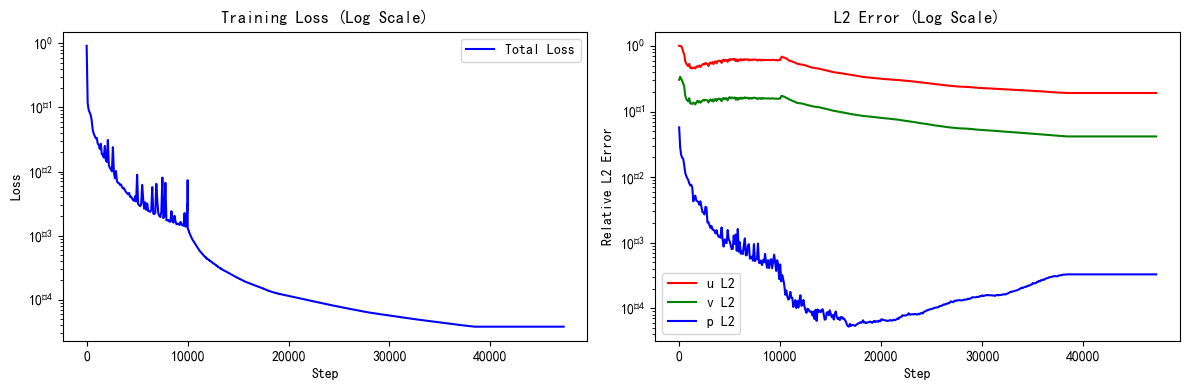

In [42]:
plt.figure(figsize=(12, 4))
# 总损失
plt.subplot(1, 2, 1)
plt.plot(loss_history["step"], loss_history["total"], 'b-', label='Total Loss')
plt.xlabel("Step")
plt.ylabel("Loss")
plt.yscale("log")
plt.legend()
plt.title("Training Loss (Log Scale)")

# L2误差
plt.subplot(1, 2, 2)
plt.plot(l2_error_history["step"], l2_error_history["u_l2"], 'r-', label='u L2')
plt.plot(l2_error_history["step"], l2_error_history["v_l2"], 'g-', label='v L2')
plt.plot(l2_error_history["step"], l2_error_history["p_l2"], 'b-', label='p L2')
plt.xlabel("Step")
plt.ylabel("Relative L2 Error")
plt.yscale("log")
plt.legend()
plt.title("L2 Error (Log Scale)")

plt.tight_layout()
plt.show()

In [43]:
##保存损失函数
df = pd.DataFrame(loss_history)  #字典转表格
save_path = r"loss_history.csv"
df.to_csv(save_path, index=False)  # index=False 不保存行号
##L2误差保存（修正：用l2_error_history）
df_l2 = pd.DataFrame(l2_error_history)
save_path_l2 = r"loss_l2.csv"
df_l2.to_csv(save_path_l2, index=False)

In [44]:
# 先获取预测结果（单网络版本）
pred_results = predict_regions(net, xy_coords, params)
def calc_phys_and_error(pred_results, params):

    L = params["L"]    # x方向基准长度（m）
    V_0 = params["V_0"]    # 速度基准值（m/s）
    P_0 = params["P_0"]    # 压力基准值（Pa）
    
    # 2. 提取所有数据（单批次处理，无需区分区域）
    coords_star = pred_results["coords_xy"]  # 无量纲坐标 (N,2) [x*,y*]
    pred_star = pred_results["pred"]        # 无量纲预测值 (N,3) [u*,v*,p*]
    true_star = pred_results["true_uvp"]    # 无量纲真实值 (N,3) [u*,v*,p*]
    
    # 3. 无量纲 → 物理量转换
    x_phys = (coords_star[:, 0] + 1.0) * 0.5 * L  # x* ∈ [-1,1] → x_phys ∈ [0,L]
    y_phys = (coords_star[:, 1] + 1.0) * 0.5 * L  # y* ∈ [-1,1] → y_phys ∈ [0,L]
    
    # 速度/压力转换（无量纲*特征尺度=物理量）
    u_pred = pred_star[:, 0] * V_0
    v_pred = pred_star[:, 1] * V_0
    p_pred = pred_star[:, 2] * P_0
    u_true = true_star[:, 0] * V_0
    v_true = true_star[:, 1] * V_0
    p_true = true_star[:, 2] * P_0

    # 4. 计算逐点绝对误差
    u_err_abs = np.abs(u_pred - u_true)
    v_err_abs = np.abs(v_pred - v_true)
    p_err_abs = np.abs(p_pred - p_true)

    # 5. 计算全域整体相对L2误差
    global_u_l2 = calc_rel_l2(u_pred, u_true)
    global_v_l2 = calc_rel_l2(v_pred, v_true)
    global_p_l2 = calc_rel_l2(p_pred, p_true)
    
    # 6. 自动区分孔内/孔外区域（可选，保留原功能）
    xc_phys = params['xc']
    yc_phys = params['yc']
    R_phys = params['R']
    r_sq_phys = (x_phys - xc_phys)**2 + (y_phys - yc_phys)**2
    region_tag = np.where(r_sq_phys <= R_phys**2, "inside", "outside")  # 自动标记区域

    # 7. 打包成DataFrame（兼容原格式）
    df_all = pd.DataFrame({
        "x": x_phys,                      # 物理x坐标 (m)
        "y": y_phys,                      # 物理y坐标 (m)
        "u_pred": u_pred,                 # 预测u速度 (m/s)
        "v_pred": v_pred,                 # 预测v速度 (m/s)
        "p_pred": p_pred,                 # 预测压力 (Pa)
        "u_true": u_true,                 # 真实u速度 (m/s)
        "v_true": v_true,                 # 真实v速度 (m/s)
        "p_true": p_true,                 # 真实压力 (Pa)
        "u_err_abs": u_err_abs,           # u逐点绝对误差 (m/s)
        "v_err_abs": v_err_abs,           # v逐点绝对误差 (m/s)
        "p_err_abs": p_err_abs,           # p逐点绝对误差 (Pa)
        "u_l2_rel": np.full_like(x_phys, global_u_l2),  # 全域u L2误差
        "v_l2_rel": np.full_like(x_phys, global_v_l2),  # 全域v L2误差
        "p_l2_rel": np.full_like(x_phys, global_p_l2),  # 全域p L2误差
        "region": region_tag              # 区域标记（inside/outside）
    })
    
    # 8. 打印全域整体L2误差
    print("\n===== 全域整体L2误差 =====")
    print(f"全域u速度整体相对L2误差：{global_u_l2:.6f}")
    print(f"全域v速度整体相对L2误差：{global_v_l2:.6f}")
    print(f"全域p压力整体相对L2误差：{global_p_l2:.6f}") 

    return df_all
# 执行误差计算并保存CSV
df_all = calc_phys_and_error(pred_results, params)
# 保存到CSV（注意路径转义，建议用正斜杠或原始字符串）
df_all.to_csv(r"64.csv", index=False, encoding="utf-8")


===== 全域整体L2误差 =====
全域u速度整体相对L2误差：0.191957
全域v速度整体相对L2误差：0.041745
全域p压力整体相对L2误差：0.000329


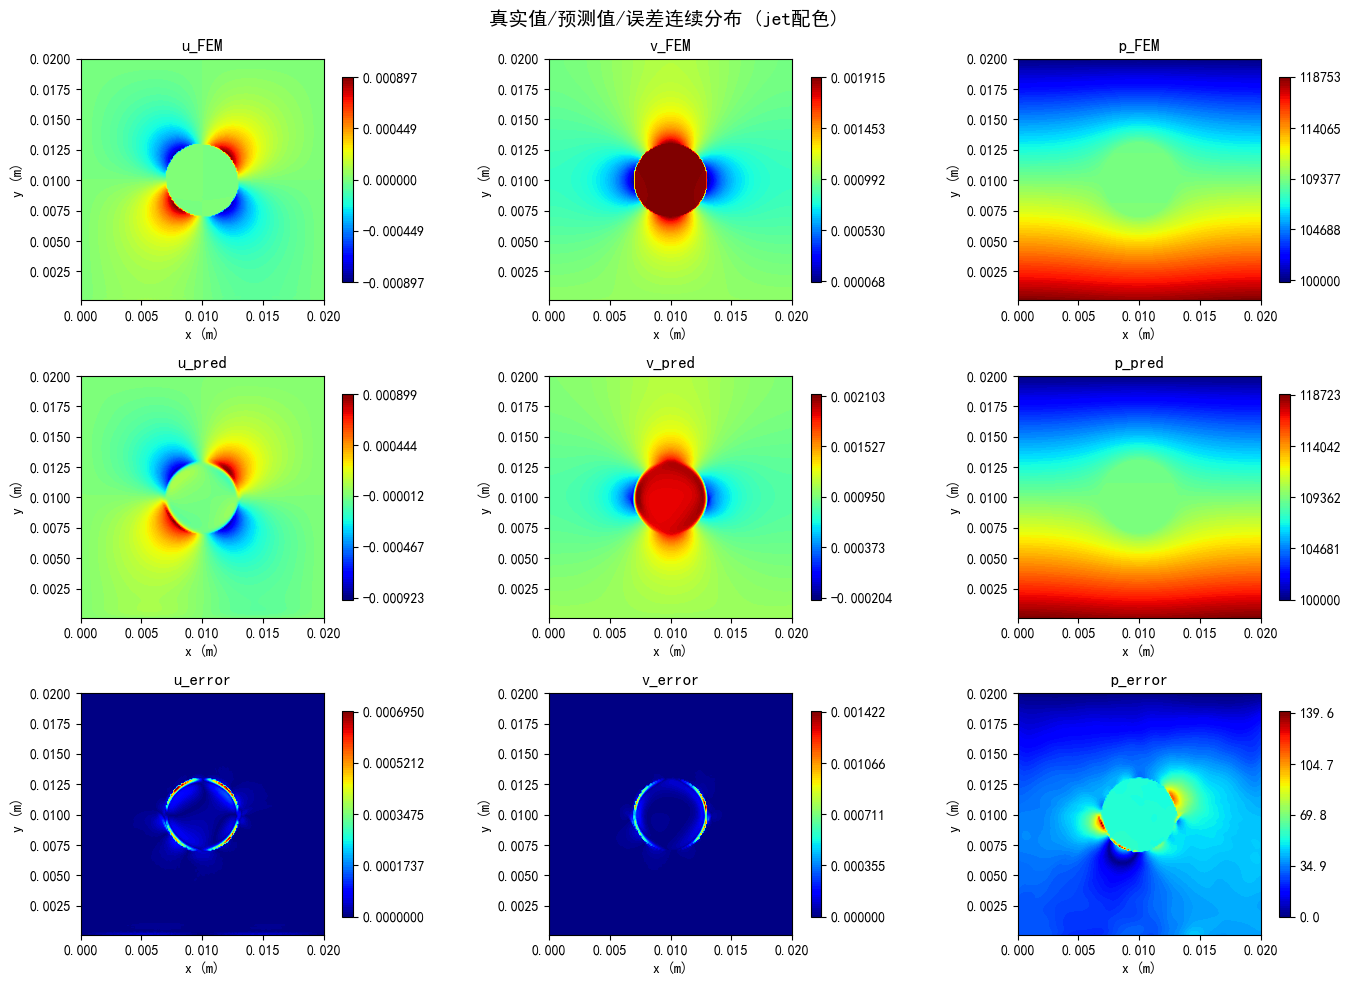

In [45]:
# 基础设置
import matplotlib.pyplot as plt
plt.rcParams["font.sans-serif"] = ["SimHei"]
plt.rcParams["axes.unicode_minus"] = False
# 读取数据
df = pd.read_csv(r"64.csv", encoding="utf-8")
# 创建3×3子图
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
fig.suptitle("真实值/预测值/误差连续分布 (jet配色)", fontsize=14)
# 定义维度和标题
dims = ['u', 'v', 'p']
titles = [
    ['u_FEM', 'v_FEM', 'p_FEM'],
    ['u_pred', 'v_pred', 'p_pred'],
    ['u_error', 'v_error', 'p_error']
]
# 逐个子图绘制连续热力图
for row in range(3):
    for col in range(3):
        ax = axes[row, col]
        dim = dims[col]

        # 提取坐标和对应数值
        x = df['x'].values
        y = df['y'].values
        if row == 0:
            val = df[f'{dim}_true'].values  # 真实值
        elif row == 1:
            val = df[f'{dim}_pred'].values  # 预测值
        else:
            val = df[f'{dim}_err_abs'].values  # 误差

        # 关键1：计算当前子图数值的极值（排除NaN）
        z_min = np.nanmin(val)
        z_max = np.nanmax(val)
        
        # 关键2：生成包含极值的5个均匀刻度（min+3个中间+max）
        ticks = np.linspace(z_min, z_max, num=5)
        
        # 核心：绘制连续三角插值填充图（适配不规则坐标）
        # 加vmin/vmax保证颜色范围精准匹配当前子图极值
        cntr = ax.tricontourf(
            x, y, val, 
            levels=100, 
            cmap='jet',
            vmin=z_min,  # 绑定最小值
            vmax=z_max   # 绑定最大值
        )

        # 关键3：只加一次颜色条，用生成的刻度（包含极值+中间值）
        fig.colorbar(cntr, ax=ax, shrink=0.85, ticks=ticks)
        
        # 子图标注
        ax.set_title(titles[row][col])
        ax.set_xlabel('x (m)')
        ax.set_ylabel('y (m)')
        ax.set_aspect("equal", adjustable="box")  # 保证xy等比例
# 调整间距+保存高清图
plt.tight_layout()
# plt.savefig(r"D:\Py_project\pythonProject\整理\3×3_连续热力图_jet.png", dpi=300)
plt.show()

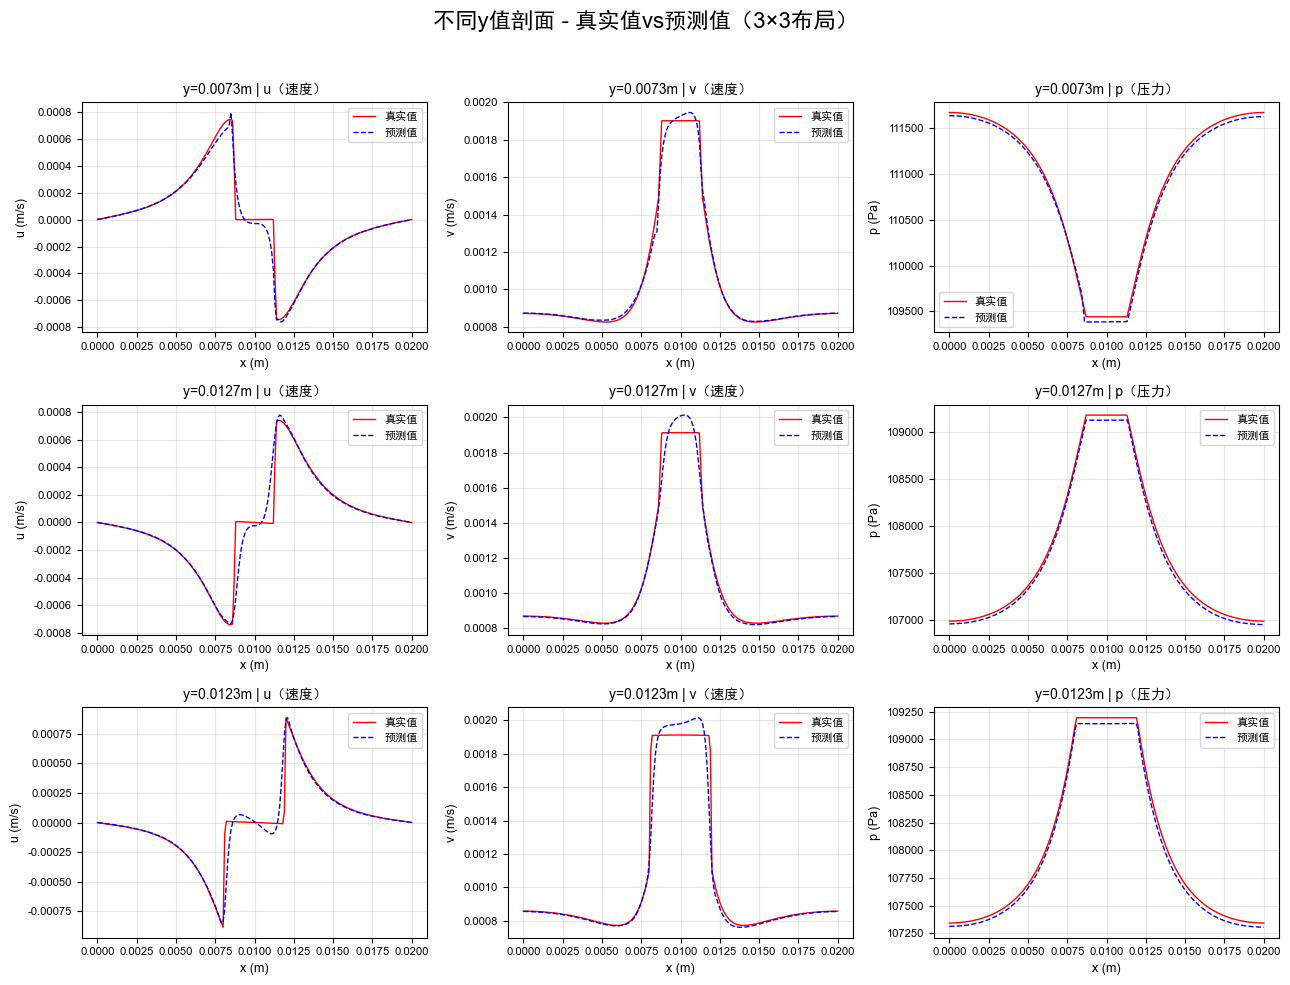

In [46]:
# ===================== ：3×3布局 - 指定y值的剖面线图 =====================
# 定义要提取的y值（行）和维度（列）

y_values = [0.0073, 0.0127, 0.0123]
dims = ['u', 'v', 'p']
# 定义线图的颜色和样式
colors = {'true': 'red', 'pred': 'blue'}
styles = {'true': '-', 'pred': '--'}
plt.rcParams['font.family'] = ['Arial', 'SimHei', 'DejaVu Sans']  # 优先Arial，其次黑体（支持中文）
plt.rcParams['axes.unicode_minus'] = False  # 解决负号显示问题
plt.rcParams['font.sans-serif'] = ['Arial', 'SimHei']  # 补充sans-serif字体列表
# 创建3×3子图布局
fig, axes = plt.subplots(3, 3, figsize=(13, 10))
fig.suptitle("不同y值剖面 - 真实值vs预测值（3×3布局）", fontsize=16, y=0.98)

# 遍历3行（y值）×3列（维度）绘制子图
for row in range(3):
    y_val = y_values[row]  # 行对应y值：0.3/0.7/1.2
    for col in range(3):
        dim = dims[col]     # 列对应维度：u/v/p
        ax = axes[row, col] # 获取当前子图
        
        # 筛选y≈y_val的点（允许±0.01的误差）
        df_slice = df[np.isclose(df['y'], y_val, atol=0.00001)]
        # 按x坐标排序（保证线图有序）
        df_slice = df_slice.sort_values(by='x')
        
        # 绘制真实值线
        ax.plot(df_slice['x'], df_slice[f'{dim}_true'], 
                color=colors['true'], linestyle=styles['true'], 
                label='真实值', linewidth=1)
        # 绘制预测值线
        ax.plot(df_slice['x'], df_slice[f'{dim}_pred'], 
                color=colors['pred'], linestyle=styles['pred'], 
                label='预测值', linewidth=1)
        
        # 子图标注
        ax.set_title(f'y={y_val}m | {dim}（{"速度" if dim in ["u","v"] else "压力"}）', fontsize=10)
        ax.set_xlabel('x (m)', fontsize=9)
        ax.set_ylabel(f'{dim} ({"m/s" if dim in ["u","v"] else "Pa"})', fontsize=9)
        ax.legend(loc='best', fontsize=8)
        ax.grid(alpha=0.3)
        ax.tick_params(axis='both', labelsize=8)

# 调整子图间距，避免重叠
plt.tight_layout(rect=[0, 0, 1, 0.96])
# 保存高清图（可选）
# plt.savefig(r"D:\Py_project\pythonProject\整理\3×3_剖面线图(y=0.3,0.7,1.2).png", dpi=300)
plt.show()